# Lab 8-03：用 Langfuse 替 RAG 打點，找出慢在哪、貴在哪

**目標**：用 Langfuse SDK 替 mini RAG 的每一步（檢索、生成、judge）打點，把 judge 分數寫回 trace，
再把收到的資料畫成延遲分布、每題 token、單題瀑布圖，做一次錯誤分析。

**你會學到**
- Langfuse 的資料模型：trace → observation（span／retriever／generation／evaluator）→ score
- v3 之後的 SDK 是建在 OpenTelemetry 上，舊教學的寫法為什麼對不上
- 沒有帳號也能跑：把 span 收在本機記憶體裡看
- 兩種打點寫法：context manager 和 `@observe` 裝飾器
- 用 trace 回答「慢在哪、貴在哪、錯在哪」

**前置**：Lab 8-01（`judge.py`）。trace／span／generation 的原理見 `00_concepts.md` 第 5 節。
Langfuse 帳號選填：沒有金鑰時，這本會在本機收 span，不會上傳任何資料。

**對應投影片**：「拆解一條 trace」「選型：可觀測性工具」

![Langfuse 的分層：你的程式、Langfuse SDK、OpenTelemetry span，往下送到雲端、自架或本機記憶體](images/langfuse_layers.jpg)

*圖：由上往下讀。你的程式呼叫 SDK，SDK 把每一步包成 OpenTelemetry span（朱紅框），再由 exporter 送到雲端、自架伺服器或本機記憶體；
分數不是 span，走左邊那條虛線的「分數 API」。沒有金鑰時，本 notebook 走最右邊的本機記憶體。*

## Step 1：原理和平台的對照

`00_concepts.md` 第 5 節示範過：最小的 trace 只要一個 context manager，每一步寫一行 JSONL。
Langfuse 做的是同一件事，只是欄位有名字、有父子關係、有介面：

| 最小 JSONL 的欄位 | Langfuse 裡叫什麼 |
|---|---|
| `trace_id` | trace id（OTel 的 32 位 hex） |
| `step` = retrieve／generate／judge | observation，`as_type` = `retriever`／`generation`／`evaluator` |
| `start`、`latency_ms` | span 的 start_time、end_time（自動記） |
| `input`、`output`（截短） | `input`、`output`（完整保存） |
| `prompt_tokens`、`completion_tokens` | generation 的 `usage_details`（`input`、`output`） |
| judge 分數寫在 output | score：獨立物件，可篩選、可做資料集 |
| 無 | `session_id`、`tags`、`metadata`、`model`、`model_parameters`、成本換算 |

## Step 2：有沒有 Langfuse 帳號？

需要三個環境變數。新版 SDK 用 `LANGFUSE_BASE_URL`；`LANGFUSE_HOST` 是舊名稱，仍然認得。

In [1]:
import os

from dotenv import load_dotenv

load_dotenv()

LIVE = bool(os.getenv("LANGFUSE_PUBLIC_KEY") and os.getenv("LANGFUSE_SECRET_KEY")
            and (os.getenv("LANGFUSE_BASE_URL") or os.getenv("LANGFUSE_HOST")))

if LIVE:
    print("找到 Langfuse 金鑰，trace 會送到：", os.getenv("LANGFUSE_BASE_URL") or os.getenv("LANGFUSE_HOST"))
else:
    print("""沒有 Langfuse 金鑰，這本改用「本機模式」：span 只收在記憶體裡，不會上傳。

想接上真的 Langfuse，二選一：
  1. 雲端免費方案：到 https://cloud.langfuse.com 註冊 → 建 project → Settings → API Keys
  2. 自架（需要 Docker，約數 GB 磁碟）：照 https://langfuse.com/self-hosting 用 docker compose 起服務，
     打開 http://localhost:3000 建 project 拿金鑰

再把這三行加到 .env，重開 kernel：
  LANGFUSE_PUBLIC_KEY=pk-lf-...
  LANGFUSE_SECRET_KEY=sk-lf-...
  LANGFUSE_BASE_URL=https://cloud.langfuse.com   # 自架就填 http://localhost:3000""")

沒有 Langfuse 金鑰，這本改用「本機模式」：span 只收在記憶體裡，不會上傳。

想接上真的 Langfuse，二選一：
  1. 雲端免費方案：到 https://cloud.langfuse.com 註冊 → 建 project → Settings → API Keys
  2. 自架（需要 Docker，約數 GB 磁碟）：照 https://langfuse.com/self-hosting 用 docker compose 起服務，
     打開 http://localhost:3000 建 project 拿金鑰

再把這三行加到 .env，重開 kernel：
  LANGFUSE_PUBLIC_KEY=pk-lf-...
  LANGFUSE_SECRET_KEY=sk-lf-...
  LANGFUSE_BASE_URL=https://cloud.langfuse.com   # 自架就填 http://localhost:3000


## Step 3：建立 client

Langfuse v3 起整個 SDK 改建在 OpenTelemetry 上：每個 observation 就是一個 OTel span，由 exporter 送出去。
本機模式就是把 exporter 換成 OTel 內建的 `InMemorySpanExporter`——SDK 其他部分完全一樣。

In [2]:
from langfuse import Langfuse, observe, propagate_attributes
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter

if LIVE:
    lf = Langfuse()  # 從環境變數讀金鑰與網址
    print("金鑰檢查：", lf.auth_check())
    memory = None
else:
    memory = InMemorySpanExporter()
    lf = Langfuse(public_key="pk-lf-local", secret_key="sk-lf-local",
                  base_url="http://localhost:3000", span_exporter=memory)
    print("本機模式：span 收進 InMemorySpanExporter")

本機模式：span 收進 InMemorySpanExporter


## Step 4：新舊寫法對照

網路上很多 Langfuse 範例是 v2 寫法，貼進新版會直接報錯。以本機安裝的 5.2 原始碼為準：

| 用途 | v2（已移除） | v3（v4 起移除） | 本版（4.x 起、5.x 沿用） |
|---|---|---|---|
| 開一個 trace | `lf.trace(name=...)` | `lf.start_as_current_span(...)` | `lf.start_as_current_observation(name=..., as_type="span")` |
| 記一次 LLM 呼叫 | `trace.generation(...)` | `lf.start_as_current_generation(...)` | `lf.start_as_current_observation(..., as_type="generation")` |
| 設 trace 屬性 | `trace.update(user_id=...)` | `span.update_trace(...)` | `with propagate_attributes(session_id=..., tags=...)` |
| 設 trace 的輸入輸出 | `trace.update(input=...)` | `span.update_trace(input=...)` | 在最外層 observation 上 `root.update(input=..., output=...)`（v4 的 `set_current_trace_io` 在 v5 移除） |
| 寫分數 | `lf.score(...)` | `span.score_trace(...)` | `lf.score_current_trace(...)` 或 `lf.create_score(...)` |

用程式確認一下，不要相信記憶（包括這張表）：

官方遷移指南：[v3 → v4](https://langfuse.com/docs/observability/sdk/upgrade-path/python-v3-to-v4)、[v4 → v5](https://langfuse.com/docs/observability/sdk/upgrade-path/python-v4-to-v5)。v5 對打點寫法沒有新的破壞性變更，主要是移除 v4 標成棄用的 REST API 方法。

In [3]:
for name in ["trace", "score", "start_as_current_span", "start_as_current_generation",
             "start_as_current_observation", "score_current_trace", "create_score"]:
    print(f"{name:30s} {'有' if hasattr(lf, name) else '沒有'}")

trace                          沒有
score                          沒有
start_as_current_span          沒有
start_as_current_generation    沒有
start_as_current_observation   有
score_current_trace            有
create_score                   有


## Step 5：替 mini RAG 打點

每一步包一個 `lf.start_as_current_observation(...)`（跟 `00_concepts.md` 裡手寫的 `span(...)` 是同一個形狀）：
- 外層一個 `chain`，代表整題
- 裡面 `retriever`、`generation`、`evaluator` 三個 observation，自動成為它的子節點
- `propagate_attributes` 把 `session_id`、`tags`、`metadata` 傳給這個 trace 裡的每個 span

In [4]:
from judge import judge
from mini_rag import MODEL, MiniRAG, load_eval_set, load_faq

import time

rag = MiniRAG(load_faq())
trace_ids = {}
records = []  # 同時自己留一份表格，等一下畫圖用（有沒有金鑰都能畫）


def lf_answer(item: dict, top_k: int = 3, prompt: str = "v1") -> dict:
    with lf.start_as_current_observation(name="rag-question", as_type="chain",
                                         input={"question": item["question"]}) as root:
        with propagate_attributes(session_id="m8-03-demo", tags=[f"prompt-{prompt}", f"top_k-{top_k}"],
                                  metadata={"qid": item["id"]}):
            with lf.start_as_current_observation(name="retrieve", as_type="retriever",
                                                 input=item["question"]) as obs:
                t0 = time.perf_counter()
                hits = rag.retrieve(item["question"], top_k)
                retrieve_ms = (time.perf_counter() - t0) * 1000
                obs.update(output=[{"id": h["id"], "score": round(h["score"], 3)} for h in hits])

            with lf.start_as_current_observation(name="generate", as_type="generation", model=MODEL,
                                                 model_parameters={"temperature": 0},
                                                 input=item["question"]) as gen_obs:
                gen = rag.generate(item["question"], hits, prompt)
                gen_obs.update(output=gen["answer"], usage_details={
                    "input": gen["prompt_tokens"], "output": gen["completion_tokens"]})

            with lf.start_as_current_observation(name="judge", as_type="evaluator",
                                                 input={"reference": item["reference"]}) as ev:
                v = judge(item["question"], item["reference"], gen["answer"])
                ev.update(output={"score": v["score"], "passed": v["passed"], "reason": v["reason"]})

            if LIVE:  # 分數走 REST API，只有連得上伺服器才送
                lf.score_current_trace(name="judge_score", value=v["score"], comment=v["reason"])
                lf.score_current_trace(name="passed", value=float(v["passed"]), data_type="BOOLEAN")
        root.update(output=gen["answer"])
        trace_ids[item["id"]] = lf.get_current_trace_id()
    records.extend([
        {"qid": item["id"], "step": "retrieve", "latency_ms": retrieve_ms, "tokens": 0,
         "retrieved": [h["id"] for h in hits]},
        {"qid": item["id"], "step": "generate", "latency_ms": gen["latency_ms"],
         "tokens": gen["prompt_tokens"] + gen["completion_tokens"], "answer": gen["answer"]},
        {"qid": item["id"], "step": "judge", "latency_ms": v["latency_ms"],
         "tokens": v["prompt_tokens"] + v["completion_tokens"], "score": v["score"], "passed": v["passed"]},
    ])
    return {"answer": gen["answer"], "score": v["score"]}


items = load_eval_set()
for it in [items[i] for i in [0, 1, 4, 8, 12, 15, 19, 26, 27, 29, 36, 37]]:
    out = lf_answer(it)
    print(f"{it['id']} {out['score']} 分  {out['answer'][:50]}")
lf.flush()

Q01 3 分  特休要在人事系統「嵐葉」提前 3 個工作天申請。
Q02 4 分  資料中沒有提到
Q05 4 分  請了 3 天病假，診斷證明要在請假後 5 個工作天內上傳到「嵐葉」。
Q09 3 分  VPN 出現 E-217 的意思是裝置憑證過期，需要到 IT 自助入口重新下載憑證。
Q13 5 分  資料中沒有提到
Q16 4 分  不可以，事後補申請一律退回。
Q20 4 分  資料中沒有提到。
Q27 4 分  資料中沒有提到
Q28 4 分  線上服務發生 P1 事故（全站或付款功能中斷），發現者要在 15 分鐘內於 #incident 頻道
Q30 4 分  資料中沒有提到
Q37 5 分  資料中沒有提到
Q38 5 分  資料中沒有提到


## Step 6：看收到了什麼

有金鑰的話，打開下面的網址就看得到瀑布圖。本機模式就直接讀記憶體裡的 span，順便看 OTel 底層長什麼樣：

In [5]:
if LIVE:
    for qid, tid in trace_ids.items():
        print(qid, lf.get_trace_url(trace_id=tid))
else:
    spans = memory.get_finished_spans()
    print(f"收到 {len(spans)} 個 span；挑一個 generation 看它的 OTel 屬性：\n")
    g = next(s for s in spans if s.attributes.get("langfuse.observation.type") == "generation")
    for k, val in g.attributes.items():
        print(f"  {k:45s} {str(val)[:60]}")

收到 48 個 span；挑一個 generation 看它的 OTel 屬性：

  session.id                                    m8-03-demo
  langfuse.trace.metadata.qid                   "Q01"
  langfuse.trace.tags                           ('prompt-v1', 'top_k-3')
  langfuse.observation.input                    特休要提前幾天申請？
  langfuse.observation.model.name               qwen2.5:3b
  langfuse.observation.model.parameters         {"temperature": 0}
  langfuse.observation.type                     generation
  langfuse.observation.output                   特休要在人事系統「嵐葉」提前 3 個工作天申請。
  langfuse.observation.usage_details            {"input": 282, "output": 21}


跟 `00_concepts.md` 的最小 JSONL 比一比：token 數放在 `langfuse.observation.usage_details`、模型名在 `langfuse.observation.model.name`、
`session.id` 和 tags 是 `propagate_attributes` 塞進去的。**平台的資料就是一堆有命名規則的 OTel 屬性。**
這也是為什麼投影片建議「用 OTel 保持可攜」：同一批 span 換個 exporter 就能送到別的後端。

注意 `langfuse.trace.metadata.qid` 的值是 `"Q01"`（含引號）：v5 起 metadata 在 span 上一律 JSON 編碼，平台讀取時再解回來，讓巢狀欄位可以篩選。

## Step 7：慢在哪、貴在哪

有金鑰的話，Langfuse 網頁的 Tracing 頁就有這些圖。這裡用 Step 5 順手留下的 `records` 自己畫，有沒有金鑰都一樣。
延遲只看平均會被少數特別慢的請求拖著走，所以看分布、看 p50 與 p95。

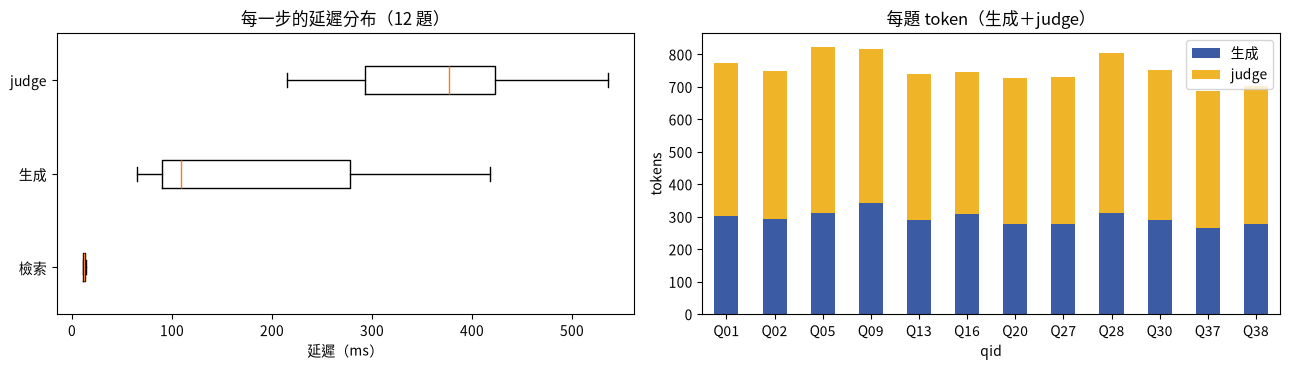

            p50    p95
step                  
generate  109.0  403.0
judge     377.0  521.0
retrieve   12.0   13.0
judge 佔總 token：61%


In [6]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from course_utils.viz import setup_cjk

setup_cjk()
df = pd.DataFrame(records)

steps = ["retrieve", "generate", "judge"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].boxplot([df[df["step"] == s]["latency_ms"] for s in steps], orientation="horizontal")
axes[0].set_yticks([1, 2, 3], ["檢索", "生成", "judge"])
axes[0].set_xlabel("延遲（ms）")
axes[0].set_title(f"每一步的延遲分布（{df['qid'].nunique()} 題）")

per_q = df.pivot_table(index="qid", columns="step", values="tokens", aggfunc="sum")[["generate", "judge"]]
per_q.plot.bar(stacked=True, ax=axes[1], color=["#3b5ba5", "#f0b429"], rot=0)
axes[1].set_ylabel("tokens")
axes[1].set_title("每題 token（生成＋judge）")
axes[1].legend(["生成", "judge"])
plt.tight_layout()
plt.show()

pct = df.groupby("step")["latency_ms"].quantile([0.5, 0.95]).unstack().round(0)
pct.columns = ["p50", "p95"]
judge_share = per_q["judge"].sum() / per_q.values.sum()
print(pct)
print(f"judge 佔總 token：{judge_share:.0%}")

# 存一份摘要，8-05 寫履歷時引用
Path("runs").mkdir(exist_ok=True)
_ = Path("runs/trace_summary.json").write_text(json.dumps({
    "n": int(df["qid"].nunique()),
    "generate_p50_ms": float(pct.loc["generate", "p50"]),
    "generate_p95_ms": float(pct.loc["generate", "p95"]),
    "judge_token_share": round(float(judge_share), 3),
}, ensure_ascii=False), encoding="utf-8")

檢索（一次 embedding＋矩陣乘法）比生成快很多，生成和 judge 才是大頭。judge 的 prompt 很長（量表＋範例），
所以評估本身就很花 token——這是「離線評估挑題庫、線上評估抽樣」的原因。

本機模式下還能直接讀 span 畫單題瀑布圖。父子關係由 OTel 的 `parent` 決定，不用自己 group by：

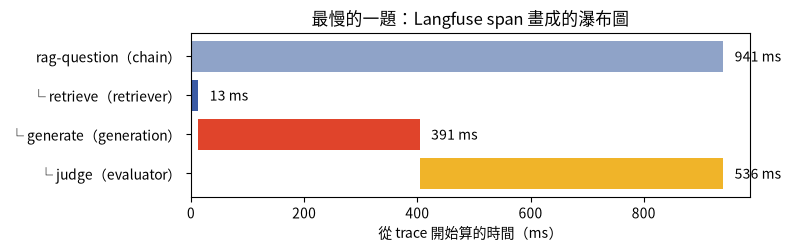

In [7]:
if LIVE:
    print("有金鑰時，到 Langfuse 網頁點開任一 trace 就是瀑布圖。")
else:
    rows = []
    for sp in memory.get_finished_spans():
        if sp.attributes.get("langfuse.observation.type") is None:
            continue
        rows.append({
            "trace_id": format(sp.context.trace_id, "032x"), "name": sp.name,
            "type": sp.attributes.get("langfuse.observation.type"),
            "is_child": sp.parent is not None,
            "start_ms": sp.start_time / 1e6, "latency_ms": (sp.end_time - sp.start_time) / 1e6,
        })
    sdf = pd.DataFrame(rows)
    slowest = sdf[sdf["type"] == "chain"].sort_values("latency_ms").iloc[-1]["trace_id"]
    one = sdf[sdf["trace_id"] == slowest].sort_values("start_ms").reset_index(drop=True)
    t0 = one["start_ms"].min()
    colors = {"chain": "#8fa3c8", "retriever": "#3b5ba5", "generation": "#e0442b", "evaluator": "#f0b429"}
    fig, ax = plt.subplots(figsize=(8, 2.6))
    for i, r in one.iterrows():
        ax.barh(i, r["latency_ms"], left=r["start_ms"] - t0, color=colors.get(r["type"], "grey"))
        ax.text(r["start_ms"] - t0 + r["latency_ms"] + 20, i, f"{r['latency_ms']:.0f} ms", va="center")
    ax.set_yticks(range(len(one)), [("└ " if r["type"] != "chain" else "") + f"{r['name']}（{r['type']}）"
                                     for _, r in one.iterrows()])
    ax.invert_yaxis()
    ax.set_xlabel("從 trace 開始算的時間（ms）")
    ax.set_title("最慢的一題：Langfuse span 畫成的瀑布圖")
    plt.tight_layout()
    plt.show()

## Step 8：錯在哪——用 trace 做錯誤分析

把 judge 沒通過的題目撈出來，對照檢索結果：正解文件有沒有被撈到？撈到了還答錯是生成的問題；沒撈到先修檢索。

In [8]:
gold = {it["id"]: it["doc_id"] for it in items}
for qid in df["qid"].unique():
    rec = {r["step"]: r for r in records if r["qid"] == qid}
    if rec["judge"]["passed"]:
        continue
    got = rec["retrieve"]["retrieved"]
    where = ("無標準文件" if gold[qid] is None
             else "檢索有撈到 → 看生成或 judge" if gold[qid] in got else "檢索沒撈到 → 先修檢索")
    print(f"{qid} {rec['judge']['score']} 分｜正解 {gold[qid]}｜撈到 {got}｜{where}")
    print(f"   回答：{rec['generate']['answer'][:60]}")

Q01 3 分｜正解 F01｜撈到 ['F01', 'F07', 'F02']｜檢索有撈到 → 看生成或 judge
   回答：特休要在人事系統「嵐葉」提前 3 個工作天申請。
Q02 4 分｜正解 F01｜撈到 ['F01', 'F02', 'F07']｜檢索有撈到 → 看生成或 judge
   回答：資料中沒有提到
Q05 4 分｜正解 F02｜撈到 ['F02', 'F09', 'F01']｜檢索有撈到 → 看生成或 judge
   回答：請了 3 天病假，診斷證明要在請假後 5 個工作天內上傳到「嵐葉」。
Q09 3 分｜正解 F04｜撈到 ['F04', 'F13', 'F15']｜檢索有撈到 → 看生成或 judge
   回答：VPN 出現 E-217 的意思是裝置憑證過期，需要到 IT 自助入口重新下載憑證。
Q13 5 分｜正解 F06｜撈到 ['F06', 'F10', 'F07']｜檢索有撈到 → 看生成或 judge
   回答：資料中沒有提到
Q20 4 分｜正解 F09｜撈到 ['F09', 'F02', 'F04']｜檢索有撈到 → 看生成或 judge
   回答：資料中沒有提到。
Q30 4 分｜正解 F14｜撈到 ['F14', 'F03', 'F16']｜檢索有撈到 → 看生成或 judge
   回答：資料中沒有提到


## Step 9：更短的寫法——`@observe`

不想改函式內容，就用裝飾器。被裝飾的函式自動成為一個 observation，巢狀呼叫自動成為子節點，輸入輸出也自動記。
代價是比較不好控制要記哪些欄位（例如 token 數還是要自己補）。

In [9]:
@observe(name="retrieve", as_type="retriever")
def retrieve_obs(question: str) -> list[str]:
    return [h["id"] for h in rag.retrieve(question, 3)]


@observe(name="rag-lite")
def rag_lite(question: str) -> list[str]:
    return retrieve_obs(question)


print(rag_lite("VPN 出現 E-217 怎麼辦？"))
lf.flush()
if not LIVE:
    print([s.name for s in memory.get_finished_spans()][-2:])

['F04', 'F13', 'F05']
['retrieve', 'rag-lite']


## Step 10：什麼時候選 Langfuse

一句話：**要開源、能自架、trace 和 prompt 管理一起顧，就選 Langfuse**（MIT 授權，`ee/` 目錄除外；2026-01 被 ClickHouse 收購，官方承諾維持 MIT）。

| 需求 | 建議 |
|---|---|
| 開源、資料不能出公司、要自架 | Langfuse（下一本的 Opik 也可以） |
| 內建評估指標多、想在 notebook 直接算分 | Opik（下一本 8-04） |
| 團隊已經全用 LangChain／LangGraph、要現成的協作與標註介面 | LangSmith（閉源 SaaS） |

不管選哪個，trace 的原理不變（`00_concepts.md` 第 5、7 節）；只要底層是 OTel，換平台就是換 exporter。

## 試試看

1. 用 `prompt="v2"` 跑同樣 12 題，tags 會變成 `prompt-v2`。有金鑰的話，到網頁用 tag 篩選，比較兩個版本的分數。
2. 在 `generate` 那個 observation 加上 `cost_details={"input": ..., "output": ...}`（自己假設一個單價），看 Langfuse 怎麼顯示成本。
3. 本機模式下，把 `InMemorySpanExporter` 換成 OTel 的 `ConsoleSpanExporter`，看 span 直接印在終端機的樣子。

## 小結

- Langfuse 的 trace／observation／score，就是最小 JSONL trace 的欄位加上名字、父子關係和介面；有了它就能回答慢在哪、貴在哪、錯在哪。
- 新版 SDK 建在 OpenTelemetry 上：v2 的 `lf.trace()` 已移除，本版統一用 `start_as_current_observation(as_type=...)`；分數走另一支 API。
- 沒有帳號也能用記憶體 exporter 看到全部資料。下一本 8-04 用 Opik 做同樣的打點，再用它的評估功能評 8-02 的回答。